Supriya K 24BAD118
Number of images: 60000
Image dimensions: (28, 28)


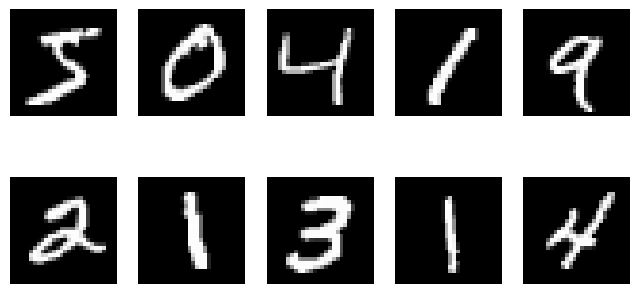

Preprocessed shape: (60000, 28, 28, 1)
Dataset prepared successfully


In [2]:

print("Supriya K 24BAD118")

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

print("Number of images:", len(x_train))
print("Image dimensions:", x_train.shape[1:])
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.axis("off")
plt.show()

dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(10000).batch(128, drop_remainder=True)

print("Preprocessed shape:", x_train.shape)
print("Dataset prepared successfully")

Supriya K 24BAD118


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 765,889 (2.92 MB)

 Trainable params: 765,761 (2.92 MB)

 Non-trainable params: 128 (512.00 B)

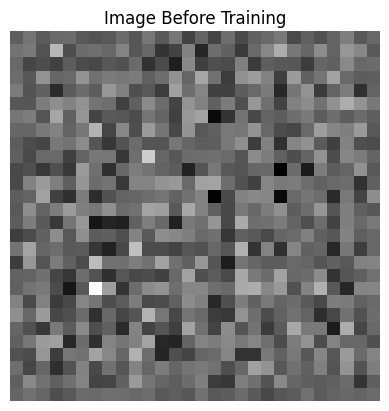

In [3]:

print("Supriya K 24BAD118")
from tensorflow.keras import layers, Model

NOISE_DIM = 100

def build_generator():
    model = tf.keras.Sequential([
        layers.Input(shape=(NOISE_DIM,)),
        layers.Dense(7 * 7 * 128),
        layers.LeakyReLU(),
        layers.Reshape((7, 7, 128)),
        layers.Conv2DTranspose(
            64, 4, strides=2, padding="same"
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Conv2DTranspose(
            1, 4, strides=2, padding="same",
            activation="tanh"
        )
    ], name="Generator")
    return model

generator = build_generator()
generator.summary()

noise = tf.random.normal([1, NOISE_DIM])
image = generator(noise, training=False)

plt.imshow(image[0, :, :, 0], cmap="gray")
plt.title("Image Before Training")
plt.axis("off")
plt.show()

In [6]:
print("Supriya K 24BAD118")
def build_discriminator():
    model = tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(64, 4, strides=2, padding="same"),
        layers.LeakyReLU(),
        layers.Dropout(0.3),
        layers.Conv2D(128, 4, strides=2, padding="same"),
        layers.LeakyReLU(),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(1, activation="sigmoid")
    ], name="Discriminator")
    return model

discriminator = build_discriminator()
discriminator.compile(
    optimizer=tf.keras.optimizers.Adam(0.0002, beta_1=0.5),
    loss="binary_crossentropy"
)

discriminator.trainable = False

gan_input = layers.Input(shape=(NOISE_DIM,))
generated_image = generator(gan_input)
gan_output = discriminator(generated_image)

gan = Model(gan_input, gan_output, name="GAN")

gan.compile(
    optimizer=tf.keras.optimizers.Adam(0.0002, beta_1=0.5),
    loss="binary_crossentropy"
)
discriminator.trainable = True

print("Discriminator trainable weights:",
      len(discriminator.trainable_weights))
print("GAN model created successfully")

Supriya K 24BAD118
Discriminator trainable weights: 6
GAN model created successfully


Supriya K 24BAD118
Epoch 1/5 | Generator Loss: 0.5126 | Discriminator Loss: 0.6453
Epoch 2/5 | Generator Loss: 0.4196 | Discriminator Loss: 0.7796
Epoch 3/5 | Generator Loss: 0.4115 | Discriminator Loss: 0.8295
Epoch 4/5 | Generator Loss: 0.4116 | Discriminator Loss: 0.8600
Epoch 5/5 | Generator Loss: 0.4104 | Discriminator Loss: 0.8762


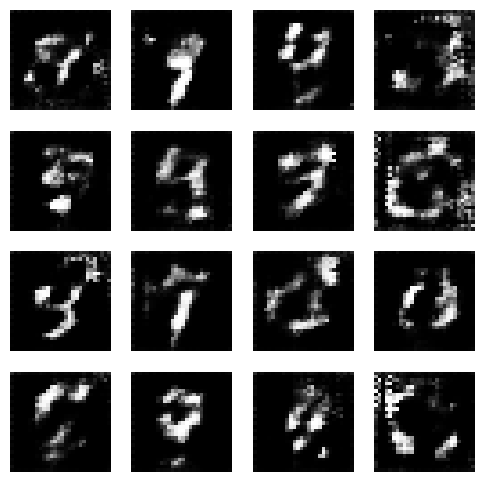

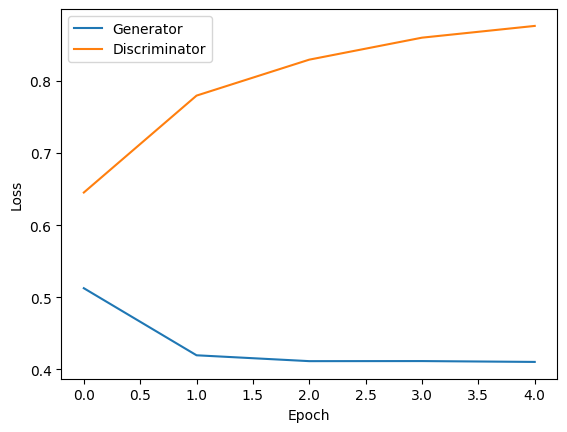

GAN training completed!


In [7]:
print("Supriya K 24BAD118")
EPOCHS = 5
g_losses = []
d_losses = []

for epoch in range(EPOCHS):
    epoch_g_loss = []
    epoch_d_loss = []

    for real_images in dataset:
        batch_size = real_images.shape[0]
        noise = tf.random.normal((batch_size, NOISE_DIM))
        fake_images = generator(noise, training=False)
        real_labels = tf.ones((batch_size, 1))
        fake_labels = tf.zeros((batch_size, 1))
        d_real = discriminator.train_on_batch(
            real_images, real_labels
        )
        d_fake = discriminator.train_on_batch(
            fake_images, fake_labels
        )
        d_loss = (
            float(np.asarray(d_real).reshape(-1)[0]) +
            float(np.asarray(d_fake).reshape(-1)[0])
        ) / 2
        noise = tf.random.normal((batch_size, NOISE_DIM))
        misleading_labels = tf.ones((batch_size, 1))
        g_loss = gan.train_on_batch(noise, misleading_labels)
        g_loss = float(np.asarray(g_loss).reshape(-1)[0])

        epoch_d_loss.append(d_loss)
        epoch_g_loss.append(g_loss)
    g_losses.append(np.mean(epoch_g_loss))
    d_losses.append(np.mean(epoch_d_loss))

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {g_losses[-1]:.4f} | "
        f"Discriminator Loss: {d_losses[-1]:.4f}"
    )
noise = tf.random.normal((16, NOISE_DIM))
images = generator(noise, training=False).numpy()

plt.figure(figsize=(6, 6))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(images[i, :, :, 0], cmap="gray")
    plt.axis("off")
plt.show()
plt.plot(g_losses, label="Generator")
plt.plot(d_losses, label="Discriminator")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

print("GAN training completed!")